# Experiment 007: same-data MC-SFT analysis plots

This notebook analyses the exploratory MC-SFT control from experiment 007. It uses all 18
probe runs: 2 scales, 3 exposure budgets and 3 seeds. Full generative evaluation is available
for seed 0 at every exposure and for all three seeds at the 8-pass headline point.

The matched comparison is base to MC-SFT against base to GRPO. The GRPO references come
from experiment 005 at 0.5B and experiment 004 at 3B. All tier metrics are recalculated from
the saved per-item predictions with the current validated tier grouping, so older result files
are not compared using stale tier labels.

This comparison evaluates the complete training setups as implemented. MC-SFT and GRPO use different objectives, learning
rates, KL treatment and compute. Each MC-SFT exposure also has its own linear learning-rate
schedule. The complete exposure curve is seed 0 only, while the 8-pass headline endpoint now
has three generative seeds. The experiment remains exploratory.

Figures are saved to `analysis/figures/007_1/` as 300 dpi PNG files.


In [17]:
# load every 007 run and the matched GRPO references
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "config.py").exists():
    raise FileNotFoundError("I could not find the repository root containing config.py")
sys.path.insert(0, str(ROOT))

from analysis.plotting import heatmap_text_color
from analysis.stats import holm, mcnemar_exact
from data.subjects import TIERS as VALIDATED_TIERS, TIERS_PROPOSAL

RES = ROOT / "results"
FIG = ROOT / "analysis" / "figures" / "007_1"
FIG.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {
    "base": "#4C78A8",
    "grpo": "#F58518",
    "p2": "#72B7B2",
    "p8": "#54A24B",
    "p32": "#B279A2",
}
TIER_COLORS = {"easy": "#59A14F", "medium": "#F28E2B", "hard": "#E15759", "overall": "#4C78A8"}
SCALES = ["B05", "B3"]
SCALE_LABELS = {"B05": "0.5B", "B3": "3B"}
EXPOSURES = ["p2", "p8", "p32"]
PASSES = {"p2": 2, "p8": 8, "p32": 32}
STEPS = {"p2": 31, "p8": 123, "p32": 490}
SEEDS = [0, 1, 2]
GROUPS = ["easy", "medium", "hard", "overall"]
METHODS = ["base", "grpo", "p2", "p8", "p32"]
METHOD_LABELS = {"base": "base", "grpo": "base + GRPO", "p2": "MC-SFT 2", "p8": "MC-SFT 8", "p32": "MC-SFT 32"}

REF_SPECS = {
    "B05": {
        "run": RES / "005_COLAB_FULL_B05_base_grpo_seed0",
        "base": RES / "base_evals" / "005_COLAB_FULL_B05",
    },
    "B3": {
        "run": RES / "004_COLAB_FULL_B3_base_grpo_seed0",
        "base": RES / "base_evals" / "004_COLAB_FULL_B3",
    },
}

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def tier_lookup(grouping):
    return {subject: tier for tier, subjects in grouping.items() for subject in subjects}

def retag(rows, grouping=VALIDATED_TIERS):
    lookup = tier_lookup(grouping)
    subject_order = {
        subject: index
        for index, subject in enumerate(
            subject for tier in ["easy", "medium", "hard"] for subject in grouping[tier]
        )
    }
    tagged = [{**row, "tier": lookup[row["subject"]]} for row in rows]
    return sorted(tagged, key=lambda row: subject_order[row["subject"]])

def accuracy(rows, group="overall"):
    selected = rows if group == "overall" else [row for row in rows if row["tier"] == group]
    return float(np.mean([bool(row["correct"]) for row in selected]))

def subject_accuracy(rows):
    output = {}
    for subject in sorted({row["subject"] for row in rows}):
        selected = [row for row in rows if row["subject"] == subject]
        output[subject] = float(np.mean([bool(row["correct"]) for row in selected]))
    return output

def signature(rows):
    return [(row["subject"], row["gold"], row["pred"], bool(row["correct"])) for row in rows]

def aligned(rows_a, rows_b):
    if len(rows_a) != len(rows_b):
        raise ValueError("I found different numbers of paired predictions")
    for row_a, row_b in zip(rows_a, rows_b):
        if (row_a["subject"], row_a["gold"]) != (row_b["subject"], row_b["gold"]):
            raise ValueError("I found prediction rows that are not aligned")

def diagnosis(rows):
    return {
        "format_compliance": float(np.mean([bool(row["format_ok"]) for row in rows])),
        "extraction_failure": float(np.mean([row["pred"] is None for row in rows])),
        "mean_length": float(np.mean([row["n_tokens"] for row in rows])),
    }

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    print("saved", name)

def run_dir(scale, exposure, seed):
    return RES / f"007_{exposure}_COLAB_FULL_{scale}_sft_only_seed{seed}"

RUNS = {}
for scale in SCALES:
    RUNS[scale] = {}
    for exposure in EXPOSURES:
        RUNS[scale][exposure] = {}
        for seed in SEEDS:
            folder = run_dir(scale, exposure, seed)
            item = {
                "folder": folder,
                "manifest": jload(folder / "manifest.json"),
                "summary": jload(folder / "summary.json"),
                "trainlog": jload(folder / "sft_trainlog.json"),
                "probe": retag(jsonl(folder / "sft_logprob_preds.jsonl")),
            }
            if seed == 0 or exposure == "p8":
                item["gen"] = retag(jsonl(folder / "sft_preds.jsonl"))
                item["eval_manifest"] = jload(folder / "sft_eval_manifest.json")
            RUNS[scale][exposure][seed] = item

REFS = {}
for scale, spec in REF_SPECS.items():
    REFS[scale] = {
        "gen": {
            "base": retag(jsonl(spec["base"] / "base_preds.jsonl")),
            "grpo": retag(jsonl(spec["run"] / "grpo_preds.jsonl")),
        },
        "probe": {
            "base": retag(jsonl(spec["base"] / "base_logprob_preds.jsonl")),
            "grpo": retag(jsonl(spec["run"] / "grpo_logprob_preds.jsonl")),
        },
    }

# use the base probe calculated inside 007 because it matches the sweep runtime
for scale in SCALES:
    base_probe_dir = RES / "base_evals" / f"007_p2_COLAB_FULL_{scale}"
    REFS[scale]["probe"]["base"] = retag(jsonl(base_probe_dir / "base_logprob_preds.jsonl"))

SUBJECTS = [subject for tier in ["easy", "medium", "hard"] for subject in VALIDATED_TIERS[tier]]
SHORT_SUBJECTS = [subject.replace("high_school_", "hs_") for subject in SUBJECTS]


## 1. Result completeness

The sweep should contain 18 probe runs, six seed-0 generative evaluations and four additional
generative evaluations for seeds 1 and 2 at the 8-pass headline point.
The checks below also confirm the training budgets, data mode, dtype, clean training commit,
prediction alignment and reuse of the same base probe.


In [18]:
# verify every planned artifact before plotting any result
health_rows = []
commits = set()
devices = set()
for scale in SCALES:
    for exposure in EXPOSURES:
        loss_counts = []
        runtimes = []
        for seed in SEEDS:
            item = RUNS[scale][exposure][seed]
            manifest = item["manifest"]
            losses = [row for row in item["trainlog"] if "loss" in row and "step" in row]
            final = item["trainlog"][-1]
            commits.add(manifest["git"]["commit"])
            devices.add(manifest["gpu"]["device"])
            loss_counts.append(len(losses))
            runtimes.append(float(final["train_runtime"]))
            assert manifest["config"]["train"]["max_steps"] == STEPS[exposure]
            assert manifest["config"]["train"]["sft_data"] == "mmlu_mc"
            assert manifest["config"]["train"]["sft_val_examples"] == 0
            assert manifest["resolved_dtype"] == "bfloat16"
            assert manifest["git"]["dirty"] is False
            assert len(item["probe"]) == 1884
            assert len(losses) == STEPS[exposure]
            if seed == 0 or exposure == "p8":
                assert len(item["gen"]) == 1884
                assert item["eval_manifest"]["completed"] is True
                aligned(item["probe"], item["gen"])
        base_dir = RES / "base_evals" / f"007_{exposure}_COLAB_FULL_{scale}"
        base_probe = retag(jsonl(base_dir / "base_logprob_preds.jsonl"))
        assert signature(base_probe) == signature(REFS[scale]["probe"]["base"])
        health_rows.append({
            "scale": SCALE_LABELS[scale],
            "exposure": PASSES[exposure],
            "steps": STEPS[exposure],
            "effective_passes": STEPS[exposure] * 16 / 245,
            "probe_seeds": len(SEEDS),
            "generative_seeds": sum("gen" in RUNS[scale][exposure][seed] for seed in SEEDS),
            "loss_rows_per_seed": "/".join(map(str, loss_counts)),
            "mean_train_minutes": np.mean(runtimes) / 60,
        })

assert len(commits) == 1
assert all("A100" in device for device in devices)
health_tbl = pd.DataFrame(health_rows).set_index(["scale", "exposure"]).round(3)
display(health_tbl)
print("training commit:", next(iter(commits))[:7])
print("gpu devices:", sorted(devices))
print("figures ->", FIG)


steps  effective_passes  probe_seeds  generative_seeds  \
scale exposure                                                           
0.5B  2            31             2.024            3                 1   
      8           123             8.033            3                 3   
      32          490            32.000            3                 1   
3B    2            31             2.024            3                 1   
      8           123             8.033            3                 3   
      32          490            32.000            3                 1   

               loss_rows_per_seed  mean_train_minutes  
scale exposure                                         
0.5B  2                  31/31/31               0.483  
      8               123/123/123               1.827  
      32              490/490/490               7.026  
3B    2                  31/31/31               0.741  
      8               123/123/123               2.752  
      32              490/490/490              10.734

training commit: 0184c33
gpu devices: ['NVIDIA A100-SXM4-40GB']
figures -> /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/analysis/figures/007_1


saved fig01_sft_loss_curves


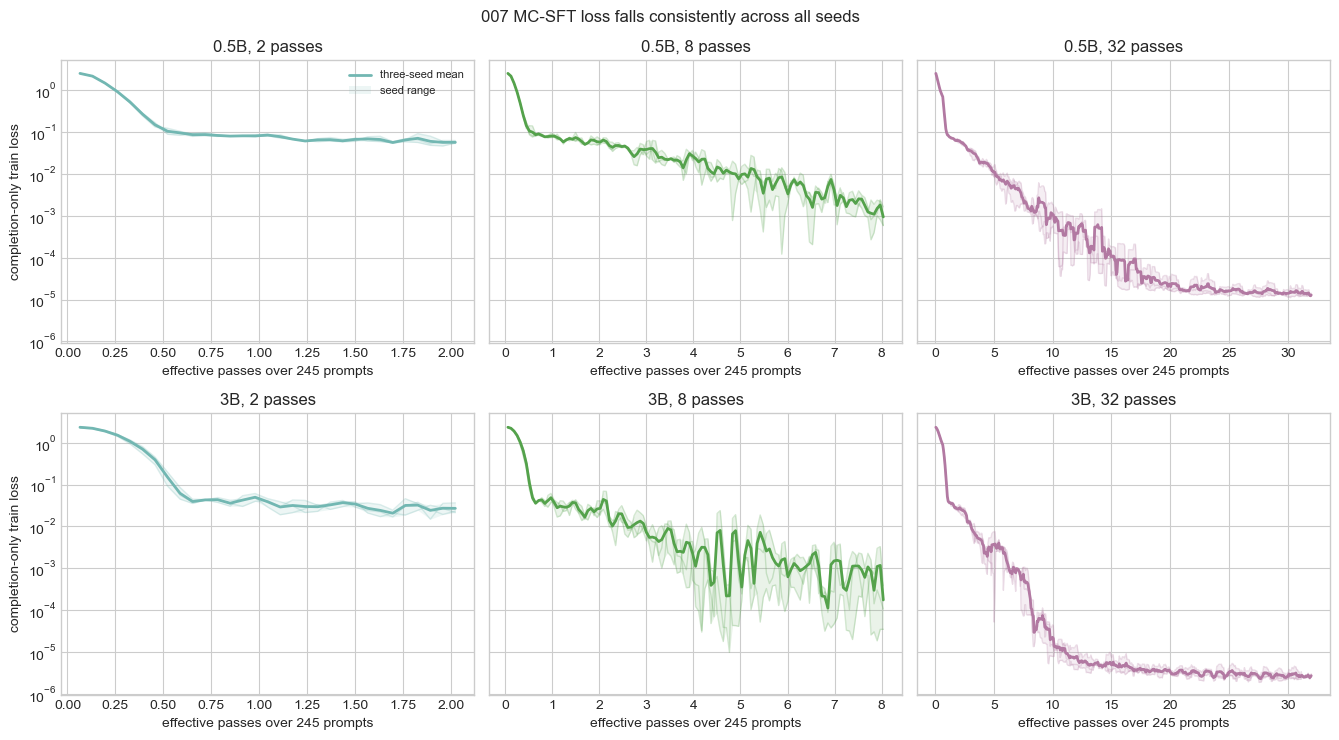

In [19]:
# plot the three-seed loss curve for every scale and training budget
fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.5), sharey=True)
for row_index, scale in enumerate(SCALES):
    for col_index, exposure in enumerate(EXPOSURES):
        ax = axes[row_index, col_index]
        seed_curves = []
        steps = None
        window = max(2, STEPS[exposure] // 45)
        for seed in SEEDS:
            losses = [entry for entry in RUNS[scale][exposure][seed]["trainlog"] if "loss" in entry and "step" in entry]
            frame = pd.DataFrame(losses)
            steps = frame["step"].to_numpy()
            smooth_loss = frame["loss"].rolling(window, min_periods=1).mean().to_numpy()
            seed_curves.append(smooth_loss)
            ax.plot(steps * 16 / 245, smooth_loss, color=COLORS[exposure], alpha=0.25, lw=1)
        curves = np.vstack(seed_curves)
        mean_curve = curves.mean(axis=0)
        ax.plot(steps * 16 / 245, mean_curve, color=COLORS[exposure], lw=2, label="three-seed mean")
        ax.fill_between(steps * 16 / 245, curves.min(axis=0), curves.max(axis=0),
                        color=COLORS[exposure], alpha=0.12, linewidth=0, label="seed range")
        ax.set_yscale("log")
        ax.set_title(f"{SCALE_LABELS[scale]}, {PASSES[exposure]} passes")
        ax.set_xlabel("effective passes over 245 prompts")
        if col_index == 0:
            ax.set_ylabel("completion-only train loss")
axes[0, 0].legend(fontsize=8)
fig.suptitle("007 MC-SFT loss falls consistently across all seeds")
fig.tight_layout()
save(fig, "fig01_sft_loss_curves")
plt.show()


## 2. Three-seed knowledge probe

The log-probability probe has three seeds at every exposure. It checks whether the
models changed their preference among A, B, C and D without requiring the trained output
format. Mean, standard deviation and the full seed range are reported together.


In [20]:
# calculate probe accuracy for every seed and current tier
probe_rows = []
for scale in SCALES:
    for exposure in EXPOSURES:
        for seed in SEEDS:
            rows = RUNS[scale][exposure][seed]["probe"]
            for group in GROUPS:
                probe_rows.append({
                    "scale": scale,
                    "exposure": exposure,
                    "passes": PASSES[exposure],
                    "seed": seed,
                    "group": group,
                    "accuracy": accuracy(rows, group),
                })
probe_df = pd.DataFrame(probe_rows)
probe_summary = (probe_df.groupby(["scale", "exposure", "passes", "group"])["accuracy"]
                 .agg(["mean", "std", "min", "max"]).reset_index())
probe_summary["base"] = probe_summary.apply(
    lambda row: accuracy(REFS[row["scale"]]["probe"]["base"], row["group"]), axis=1)
probe_summary["grpo"] = probe_summary.apply(
    lambda row: accuracy(REFS[row["scale"]]["probe"]["grpo"], row["group"]), axis=1)
probe_summary["mean_minus_base"] = probe_summary["mean"] - probe_summary["base"]

probe_tbl = probe_summary.copy()
probe_tbl["scale"] = probe_tbl["scale"].map(SCALE_LABELS)
display(probe_tbl.set_index(["scale", "exposure", "group"])
        [["mean", "std", "min", "max", "base", "grpo", "mean_minus_base"]].round(4))


mean     std     min     max    base    grpo  \
scale exposure group                                                     
0.5B  p2       easy     0.6875  0.0035  0.6837  0.6906  0.6871  0.6871   
               hard     0.3628  0.0114  0.3510  0.3737  0.3763  0.3737   
               medium   0.5172  0.0059  0.5107  0.5222  0.5172  0.5090   
               overall  0.5642  0.0040  0.5605  0.5685  0.5669  0.5637   
      p32      easy     0.6746  0.0082  0.6655  0.6815  0.6871  0.6871   
               hard     0.3350  0.0186  0.3207  0.3561  0.3763  0.3737   
               medium   0.5151  0.0147  0.5057  0.5320  0.5172  0.5090   
               overall  0.5517  0.0045  0.5488  0.5568  0.5669  0.5637   
      p8       easy     0.6769  0.0030  0.6735  0.6792  0.6871  0.6871   
               hard     0.3535  0.0025  0.3510  0.3561  0.3763  0.3737   
               medium   0.5140  0.0072  0.5090  0.5222  0.5172  0.5090   
               overall  0.5563  0.0030  0.5536  0.5594  0.5669  0.5637   
3B    p2       easy     0.8601  0.0011  0.8589  0.8612  0.8567  0.8544   
               hard     0.4966  0.0053  0.4924  0.5025  0.4899  0.4899   
               medium   0.7285  0.0025  0.7258  0.7307  0.7291  0.7291   
               overall  0.7412  0.0003  0.7410  0.7415  0.7383  0.7373   
      p32      easy     0.8582  0.0035  0.8544  0.8612  0.8567  0.8544   
               hard     0.5168  0.0193  0.5000  0.5379  0.4899  0.4899   
               medium   0.7345  0.0025  0.7323  0.7373  0.7291  0.7291   
               overall  0.7465  0.0036  0.7436  0.7505  0.7383  0.7373   
      p8       easy     0.8627  0.0013  0.8612  0.8635  0.8567  0.8544   
               hard     0.5143  0.0053  0.5101  0.5202  0.4899  0.4899   
               medium   0.7329  0.0034  0.7291  0.7356  0.7291  0.7291   
               overall  0.7475  0.0006  0.7468  0.7479  0.7383  0.7373   

                        mean_minus_base  
scale exposure group                     
0.5B  p2       easy              0.0004  
               hard             -0.0135  
               medium            0.0000  
               overall          -0.0027  
      p32      easy             -0.0125  
               hard             -0.0412  
               medium           -0.0022  
               overall          -0.0152  
      p8       easy             -0.0102  
               hard             -0.0227  
               medium           -0.0033  
               overall          -0.0106  
3B    p2       easy              0.0034  
               hard              0.0067  
               medium           -0.0005  
               overall           0.0028  
      p32      easy              0.0015  
               hard              0.0269  
               medium            0.0055  
               overall           0.0081  
      p8       easy              0.0061  
               hard              0.0244  
               medium            0.0038  
               overall           0.0092

saved fig02_probe_exposure_curve


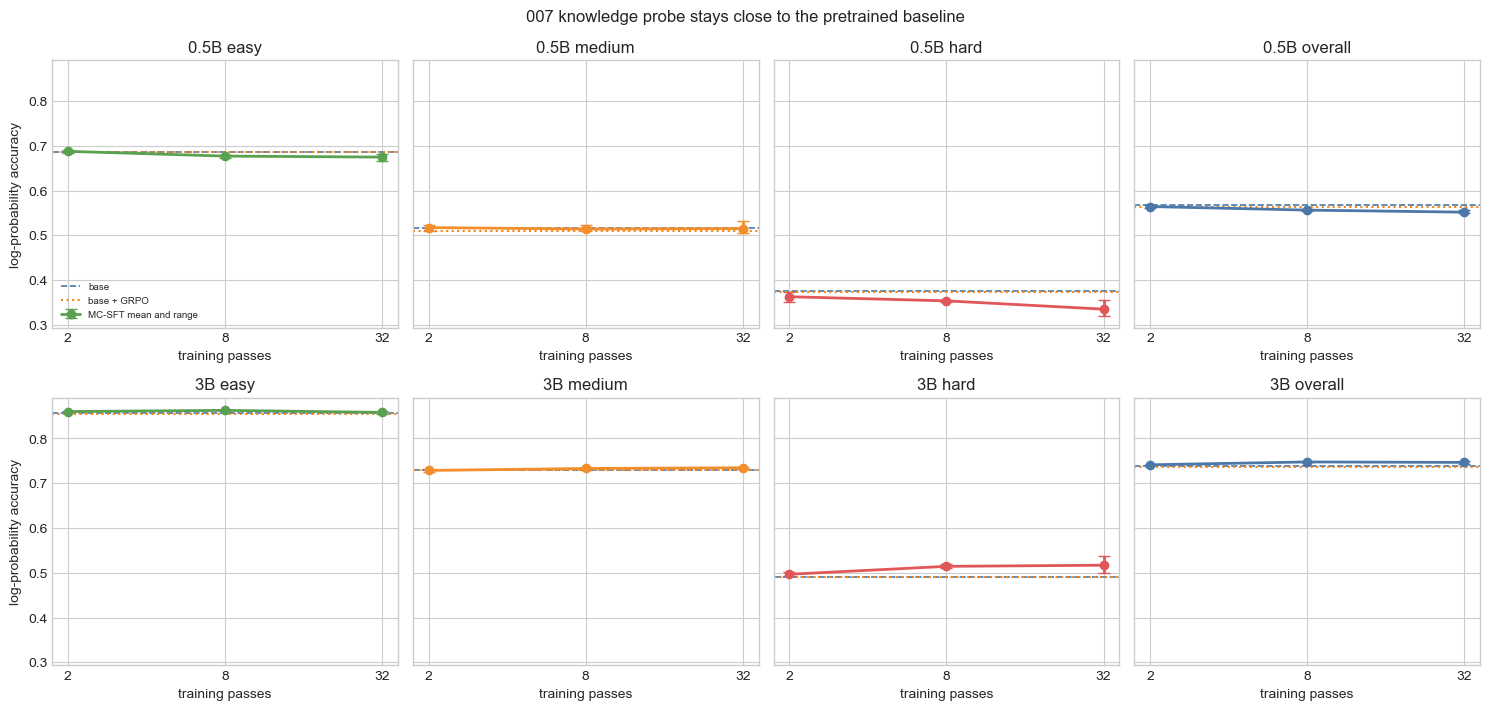

In [21]:
# plot mean probe accuracy with the full range across three seeds
fig, axes = plt.subplots(2, 4, figsize=(15, 7.2), sharey=True)
for row_index, scale in enumerate(SCALES):
    for col_index, group in enumerate(GROUPS):
        ax = axes[row_index, col_index]
        part = probe_summary[(probe_summary["scale"] == scale) & (probe_summary["group"] == group)].sort_values("passes")
        low = part["mean"] - part["min"]
        high = part["max"] - part["mean"]
        ax.errorbar(part["passes"], part["mean"], yerr=[low, high], marker="o", lw=2,
                    capsize=4, color=TIER_COLORS[group], label="MC-SFT mean and range")
        ax.axhline(part["base"].iloc[0], color=COLORS["base"], ls="--", lw=1.2, label="base")
        ax.axhline(part["grpo"].iloc[0], color=COLORS["grpo"], ls=":", lw=1.5, label="base + GRPO")
        ax.set_xscale("log", base=2)
        ax.set_xticks([2, 8, 32])
        ax.set_xticklabels(["2", "8", "32"])
        ax.set_title(f"{SCALE_LABELS[scale]} {group}")
        ax.set_xlabel("training passes")
        if col_index == 0:
            ax.set_ylabel("log-probability accuracy")
axes[0, 0].legend(fontsize=7, loc="lower left")
fig.suptitle("007 knowledge probe stays close to the pretrained baseline")
fig.tight_layout()
save(fig, "fig02_probe_exposure_curve")
plt.show()


saved fig03_probe_subject_delta


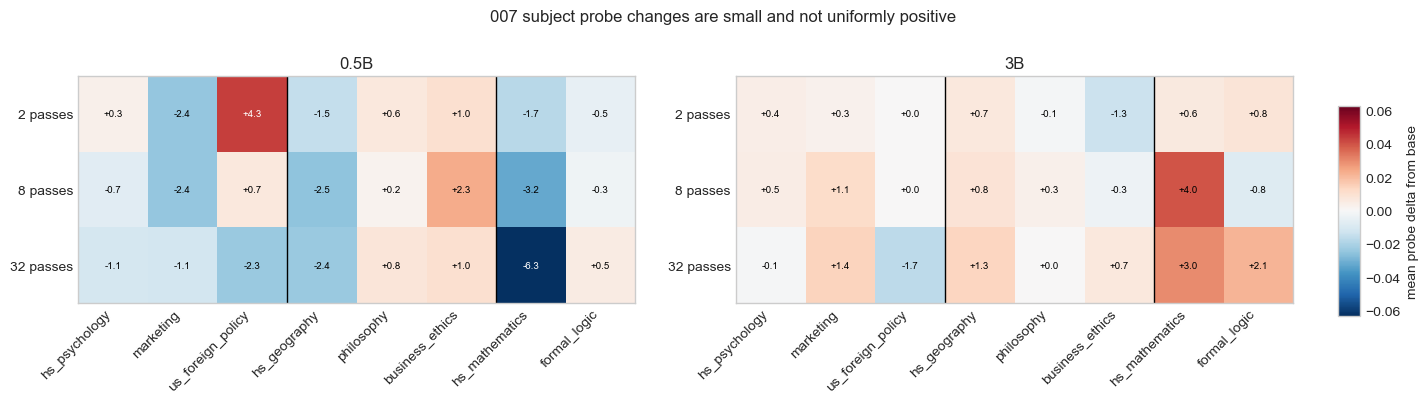

In [22]:
# show where the probe changes occur at subject level
probe_subject_rows = []
for scale in SCALES:
    base_values = subject_accuracy(REFS[scale]["probe"]["base"])
    for exposure in EXPOSURES:
        for seed in SEEDS:
            values = subject_accuracy(RUNS[scale][exposure][seed]["probe"])
            for subject in SUBJECTS:
                probe_subject_rows.append({
                    "scale": scale,
                    "exposure": exposure,
                    "seed": seed,
                    "subject": subject,
                    "delta": values[subject] - base_values[subject],
                })
probe_subject_df = pd.DataFrame(probe_subject_rows)
probe_subject_mean = probe_subject_df.groupby(["scale", "exposure", "subject"])["delta"].mean()
limit = max(abs(probe_subject_mean.min()), abs(probe_subject_mean.max()))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, scale in zip(axes, SCALES):
    matrix = np.array([
        [probe_subject_mean.loc[(scale, exposure, subject)] for subject in SUBJECTS]
        for exposure in EXPOSURES
    ])
    image = ax.imshow(matrix, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto", interpolation="nearest")
    ax.set_xticks(np.arange(len(SUBJECTS)))
    ax.set_xticklabels(SHORT_SUBJECTS, rotation=45, ha="right")
    ax.set_yticks(np.arange(len(EXPOSURES)))
    ax.set_yticklabels([f"{PASSES[exposure]} passes" for exposure in EXPOSURES])
    ax.set_title(SCALE_LABELS[scale])
    ax.grid(False)
    ax.axvline(2.5, color="black", lw=1)
    ax.axvline(5.5, color="black", lw=1)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            color = heatmap_text_color(image, matrix[i, j])
            ax.text(j, i, f"{matrix[i, j] * 100:+.1f}", ha="center", va="center", fontsize=7, color=color)
cbar_axis = fig.add_axes([0.91, 0.25, 0.015, 0.5])
fig.colorbar(image, cax=cbar_axis, label="mean probe delta from base")
fig.suptitle("007 subject probe changes are small and not uniformly positive")
fig.subplots_adjust(left=0.07, right=0.88, bottom=0.28, top=0.82, wspace=0.18)
save(fig, "fig03_probe_subject_delta")
plt.show()


## 3. Generative comparison

The main same-data question is whether MC-SFT can reproduce the free-form MMLU improvement
seen under base to GRPO. The full exposure curve remains seed 0, while the selected 8-pass
endpoint now has three 1,884-item evaluations. Base and GRPO remain the matched seed-0 A100
BF16 references, so only seed 0 provides a paired method contrast.


In [23]:
# calculate the available generative endpoints for every method
gen_rows = []
for scale in SCALES:
    for method, rows in REFS[scale]["gen"].items():
        for group in GROUPS:
            gen_rows.append({"scale": scale, "method": method, "seed": 0,
                             "group": group, "accuracy": accuracy(rows, group)})
    for exposure in EXPOSURES:
        available_seeds = SEEDS if exposure == "p8" else [0]
        for seed in available_seeds:
            rows = RUNS[scale][exposure][seed]["gen"]
            for group in GROUPS:
                gen_rows.append({"scale": scale, "method": exposure, "seed": seed,
                                 "group": group, "accuracy": accuracy(rows, group)})
gen_df = pd.DataFrame(gen_rows)
gen_summary = (gen_df.groupby(["scale", "method", "group"])["accuracy"]
               .agg(["mean", "std", "min", "max", "count"]).reset_index())
gen_seed0 = gen_df[gen_df["seed"] == 0].pivot_table(
    index=["scale", "method"], columns="group", values="accuracy")
display(gen_summary.set_index(["scale", "method", "group"]).round(4))


mean     std     min     max  count
scale method group                                         
B05   base   easy     0.2218     NaN  0.2218  0.2218      1
             hard     0.1313     NaN  0.1313  0.1313      1
             medium   0.1675     NaN  0.1675  0.1675      1
             overall  0.1852     NaN  0.1852  0.1852      1
      grpo   easy     0.4881     NaN  0.4881  0.4881      1
             hard     0.2551     NaN  0.2551  0.2551      1
             medium   0.3645     NaN  0.3645  0.3645      1
             overall  0.3992     NaN  0.3992  0.3992      1
      p2     easy     0.5176     NaN  0.5176  0.5176      1
             hard     0.2904     NaN  0.2904  0.2904      1
             medium   0.4319     NaN  0.4319  0.4319      1
             overall  0.4421     NaN  0.4421  0.4421      1
      p32    easy     0.6462     NaN  0.6462  0.6462      1
             hard     0.3409     NaN  0.3409  0.3409      1
             medium   0.4844     NaN  0.4844  0.4844      1
             overall  0.5297     NaN  0.5297  0.5297      1
      p8     easy     0.6602  0.0056  0.6564  0.6667      3
             hard     0.3510  0.0191  0.3333  0.3712      3
             medium   0.4707  0.0081  0.4614  0.4762      3
             overall  0.5340  0.0040  0.5303  0.5382      3
B3    base   easy     0.6758     NaN  0.6758  0.6758      1
             hard     0.5076     NaN  0.5076  0.5076      1
             medium   0.5386     NaN  0.5386  0.5386      1
             overall  0.5961     NaN  0.5961  0.5961      1
      grpo   easy     0.7770     NaN  0.7770  0.7770      1
             hard     0.5429     NaN  0.5429  0.5429      1
             medium   0.6190     NaN  0.6190  0.6190      1
             overall  0.6768     NaN  0.6768  0.6768      1
      p2     easy     0.8567     NaN  0.8567  0.8567      1
             hard     0.4672     NaN  0.4672  0.4672      1
             medium   0.7011     NaN  0.7011  0.7011      1
             overall  0.7245     NaN  0.7245  0.7245      1
      p32    easy     0.8476     NaN  0.8476  0.8476      1
             hard     0.4596     NaN  0.4596  0.4596      1
             medium   0.7077     NaN  0.7077  0.7077      1
             overall  0.7208     NaN  0.7208  0.7208      1
      p8     easy     0.8502  0.0007  0.8498  0.8510      3
             hard     0.5000  0.0216  0.4773  0.5202      3
             medium   0.7088  0.0019  0.7077  0.7110      3
             overall  0.7309  0.0047  0.7256  0.7346      3

saved fig04_generative_endpoints


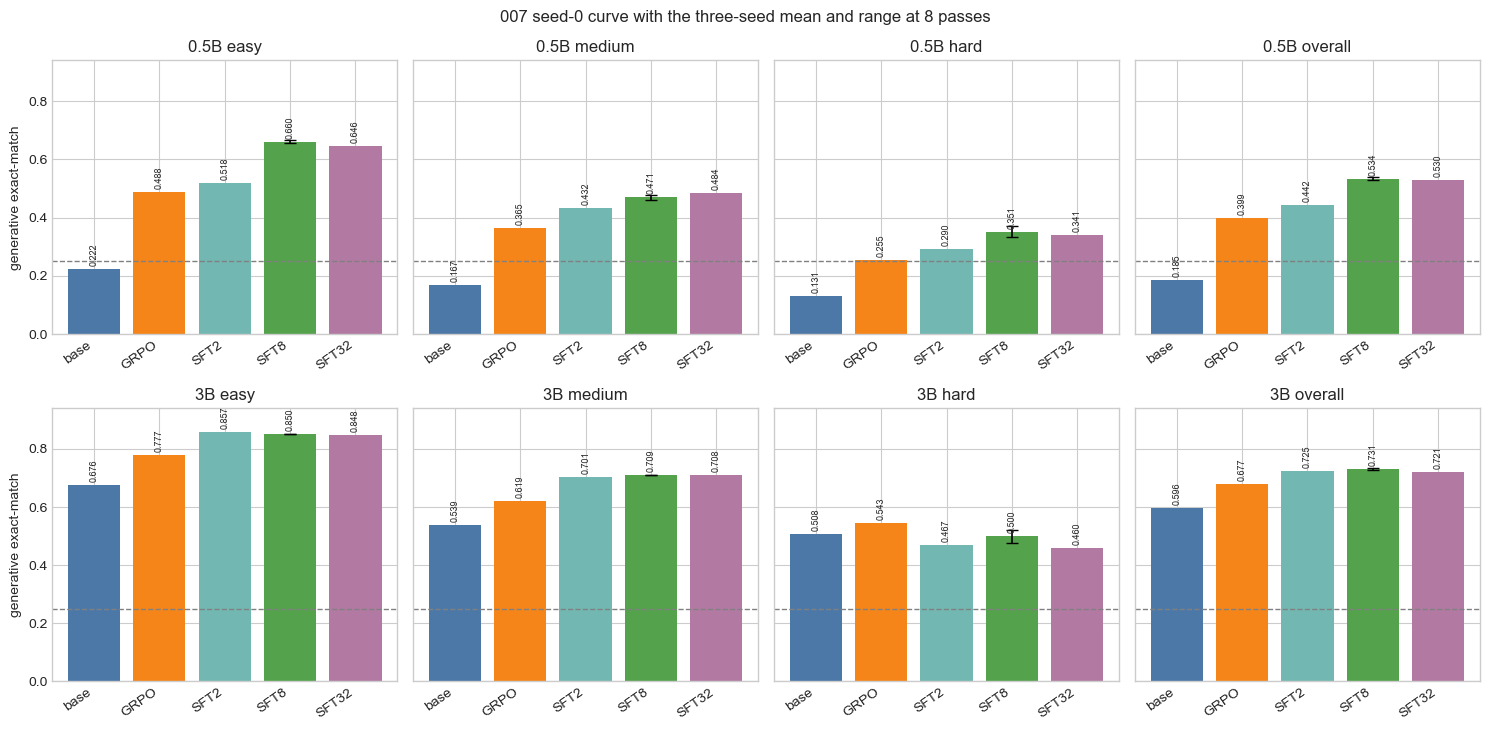

In [24]:
# compare the seed-0 curve and show the three-seed range at 8 passes
fig, axes = plt.subplots(2, 4, figsize=(15, 7.4), sharey=True)
for row_index, scale in enumerate(SCALES):
    for col_index, group in enumerate(GROUPS):
        ax = axes[row_index, col_index]
        values = [gen_seed0.loc[(scale, method), group] for method in METHODS]
        p8 = gen_summary[(gen_summary["scale"] == scale) & (gen_summary["method"] == "p8") &
                         (gen_summary["group"] == group)].iloc[0]
        values[3] = p8["mean"]
        bars = ax.bar(np.arange(len(METHODS)), values, color=[COLORS[method] for method in METHODS])
        for bar, value in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width() / 2, value + 0.018, f"{value:.3f}",
                    ha="center", fontsize=6.5, rotation=90)
        ax.errorbar(3, p8["mean"], yerr=[[p8["mean"] - p8["min"]], [p8["max"] - p8["mean"]]],
                    fmt="none", ecolor="black", capsize=4, lw=1.2)
        ax.axhline(0.25, color="grey", ls="--", lw=1)
        ax.set_xticks(np.arange(len(METHODS)))
        ax.set_xticklabels(["base", "GRPO", "SFT2", "SFT8", "SFT32"], rotation=35, ha="right")
        ax.set_title(f"{SCALE_LABELS[scale]} {group}")
        ax.set_ylim(0, 0.94)
        if col_index == 0:
            ax.set_ylabel("generative exact-match")
fig.suptitle("007 seed-0 curve with the three-seed mean and range at 8 passes")
fig.tight_layout()
save(fig, "fig04_generative_endpoints")
plt.show()


In [25]:
# calculate paired MC-SFT minus GRPO effects on the same test items
def paired_bootstrap(rows_a, rows_b, group, seed, n_boot=10000, batch=500):
    selected_a = rows_a if group == "overall" else [row for row in rows_a if row["tier"] == group]
    selected_b = rows_b if group == "overall" else [row for row in rows_b if row["tier"] == group]
    aligned(selected_a, selected_b)
    a = np.asarray([bool(row["correct"]) for row in selected_a], dtype=float)
    b = np.asarray([bool(row["correct"]) for row in selected_b], dtype=float)
    diffs = b - a
    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)
    for start in range(0, n_boot, batch):
        size = min(batch, n_boot - start)
        indices = rng.integers(0, len(diffs), size=(size, len(diffs)))
        boot[start:start + size] = diffs[indices].mean(axis=1)
    return float(diffs.mean()), float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5)), a, b

paired_rows = []
for scale_index, scale in enumerate(SCALES):
    for exposure_index, exposure in enumerate(EXPOSURES):
        for group_index, group in enumerate(GROUPS):
            delta, lo, hi, grpo_correct, sft_correct = paired_bootstrap(
                REFS[scale]["gen"]["grpo"], RUNS[scale][exposure][0]["gen"], group,
                seed=700 + scale_index * 100 + exposure_index * 10 + group_index)
            grpo_only = int(np.sum((grpo_correct == 1) & (sft_correct == 0)))
            sft_only = int(np.sum((grpo_correct == 0) & (sft_correct == 1)))
            paired_rows.append({
                "scale": scale,
                "exposure": exposure,
                "group": group,
                "delta": delta,
                "ci_lo": lo,
                "ci_hi": hi,
                "grpo_only": grpo_only,
                "sft_only": sft_only,
                "mcnemar_p": mcnemar_exact(grpo_only, sft_only),
            })
paired_df = pd.DataFrame(paired_rows)
paired_df["holm_p_tiers"] = np.nan
for scale in SCALES:
    mask = (paired_df["scale"] == scale) & (paired_df["group"] != "overall")
    paired_df.loc[mask, "holm_p_tiers"] = holm(paired_df.loc[mask, "mcnemar_p"].tolist())

paired_tbl = paired_df.copy()
paired_tbl["scale"] = paired_tbl["scale"].map(SCALE_LABELS)
display(paired_tbl.set_index(["scale", "exposure", "group"])
        [["delta", "ci_lo", "ci_hi", "grpo_only", "sft_only", "mcnemar_p", "holm_p_tiers"]]
        .round({"delta": 4, "ci_lo": 4, "ci_hi": 4, "mcnemar_p": 8, "holm_p_tiers": 8}))


delta   ci_lo   ci_hi  grpo_only  sft_only  \
scale exposure group                                                  
0.5B  p2       easy     0.0296 -0.0114  0.0694        159       185   
               medium   0.0673  0.0197  0.1149         90       131   
               hard     0.0354 -0.0278  0.0960         72        86   
               overall  0.0430  0.0149  0.0711        321       402   
      p8       easy     0.1786  0.1411  0.2162         78       235   
               medium   0.0969  0.0525  0.1412         67       126   
               hard     0.1162  0.0530  0.1768         57       103   
               overall  0.1391  0.1120  0.1651        202       464   
      p32      easy     0.1581  0.1206  0.1957         82       221   
               medium   0.1199  0.0755  0.1642         66       139   
               hard     0.0859  0.0253  0.1465         63        97   
               overall  0.1306  0.1040  0.1566        211       457   
3B    p2       easy     0.0796  0.0557  0.1047         31       101   
               medium   0.0821  0.0460  0.1182         41        91   
               hard    -0.0758 -0.1338 -0.0152         87        57   
               overall  0.0478  0.0271  0.0690        159       249   
      p8       easy     0.0739  0.0489  0.0990         34        99   
               medium   0.0920  0.0558  0.1281         38        94   
               hard    -0.0404 -0.1010  0.0202         83        67   
               overall  0.0557  0.0350  0.0770        155       260   
      p32      easy     0.0705  0.0455  0.0967         35        97   
               medium   0.0887  0.0525  0.1264         42        96   
               hard    -0.0833 -0.1439 -0.0227         94        61   
               overall  0.0441  0.0228  0.0658        171       254   

                           mcnemar_p  holm_p_tiers  
scale exposure group                                
0.5B  p2       easy     1.776019e-01  3.552037e-01  
               medium   6.994730e-03  2.797892e-02  
               hard     3.010155e-01  3.552037e-01  
               overall  2.901960e-03           NaN  
      p8       easy     0.000000e+00  0.000000e+00  
               medium   2.604000e-05  1.562600e-04  
               hard     3.438600e-04  1.719290e-03  
               overall  0.000000e+00           NaN  
      p32      easy     0.000000e+00  0.000000e+00  
               medium   3.800000e-07  2.630000e-06  
               hard     8.873590e-03  2.797892e-02  
               overall  0.000000e+00           NaN  
3B    p2       easy     0.000000e+00  1.000000e-08  
               medium   1.606000e-05  6.423000e-05  
               hard     1.537051e-02  3.074103e-02  
               overall  9.730000e-06           NaN  
      p8       easy     1.000000e-08  1.200000e-07  
               medium   1.190000e-06  7.120000e-06  
               hard     2.205448e-01  2.205448e-01  
               overall  2.900000e-07           NaN  
      p32      easy     6.000000e-08  4.500000e-07  
               medium   4.940000e-06  2.469000e-05  
               hard     9.932670e-03  2.979801e-02  
               overall  6.627000e-05           NaN

saved fig05_paired_delta_vs_grpo


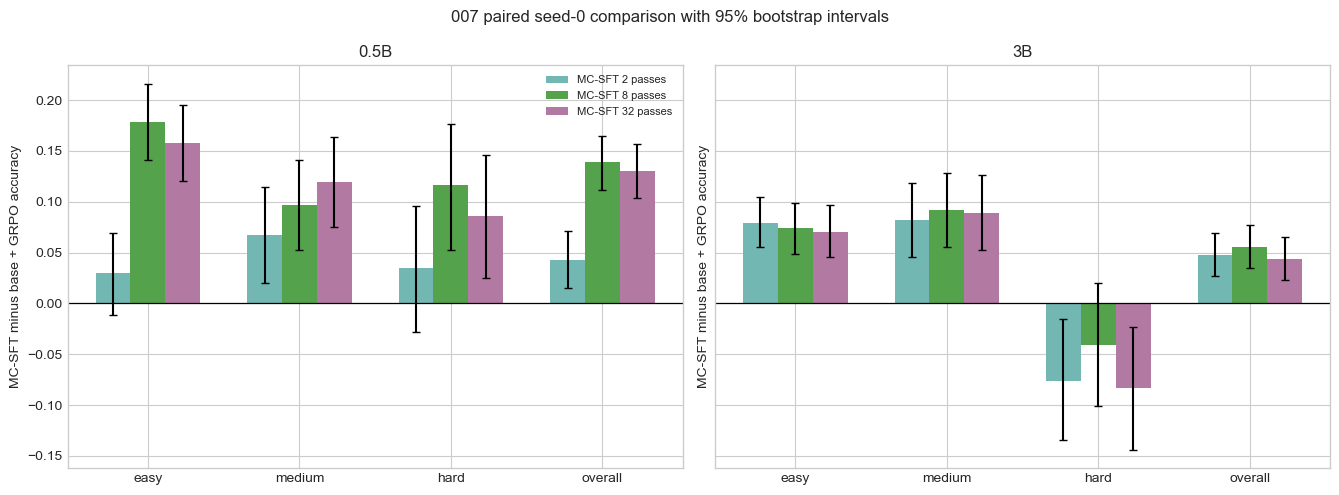

In [26]:
# plot the paired advantage or disadvantage against base to GRPO
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5), sharey=True)
x = np.arange(len(GROUPS))
width = 0.23
for ax, scale in zip(axes, SCALES):
    for index, exposure in enumerate(EXPOSURES):
        part = paired_df[(paired_df["scale"] == scale) & (paired_df["exposure"] == exposure)].set_index("group").loc[GROUPS]
        values = part["delta"].to_numpy()
        errors = np.vstack([values - part["ci_lo"].to_numpy(), part["ci_hi"].to_numpy() - values])
        ax.bar(x + (index - 1) * width, values, width, yerr=errors, capsize=3,
               color=COLORS[exposure], label=f"MC-SFT {PASSES[exposure]} passes")
    ax.axhline(0, color="black", lw=0.9)
    ax.set_xticks(x)
    ax.set_xticklabels(GROUPS)
    ax.set_title(SCALE_LABELS[scale])
    ax.set_ylabel("MC-SFT minus base + GRPO accuracy")
axes[0].legend(fontsize=8)
fig.suptitle("007 paired seed-0 comparison with 95% bootstrap intervals")
fig.tight_layout()
save(fig, "fig05_paired_delta_vs_grpo")
plt.show()


## 4. What mechanism changed

Generation and the letter probe are shown together because a large generative movement with
a flat probe suggests improved answer expression rather than a large increase in encoded MMLU
knowledge. Format compliance, answer extraction and response length show how directly each
method learns the requested output protocol.


saved fig06_generation_vs_probe


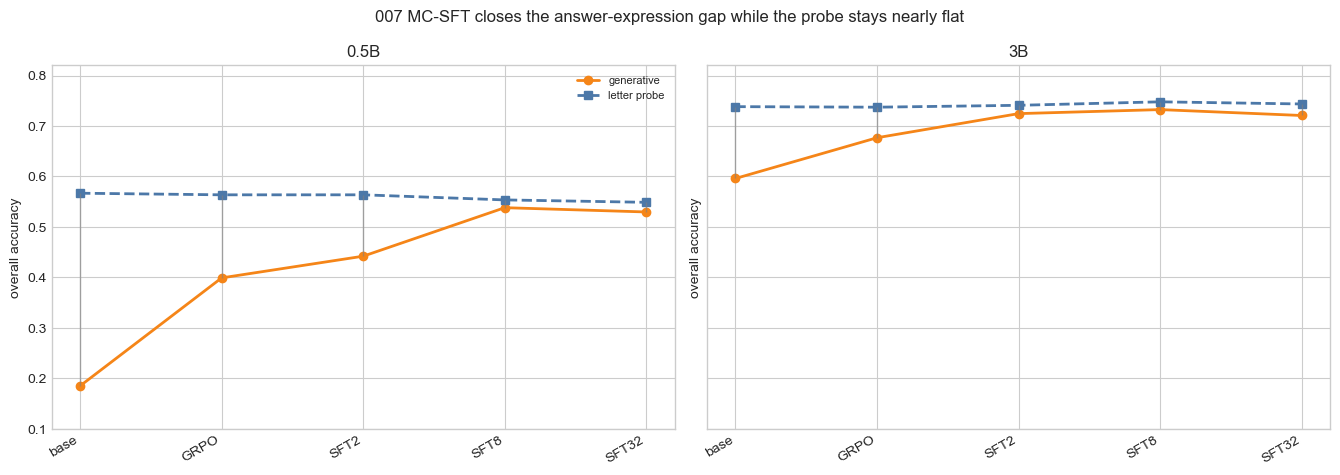

In [27]:
# compare overall generation with the seed-0 knowledge probe
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), sharey=True)
for ax, scale in zip(axes, SCALES):
    gen_values = [gen_seed0.loc[(scale, method), "overall"] for method in METHODS]
    probe_values = [
        accuracy(REFS[scale]["probe"]["base"], "overall"),
        accuracy(REFS[scale]["probe"]["grpo"], "overall"),
        *[accuracy(RUNS[scale][exposure][0]["probe"], "overall") for exposure in EXPOSURES],
    ]
    positions = np.arange(len(METHODS))
    ax.plot(positions, gen_values, "o-", color=COLORS["grpo"], lw=2, label="generative")
    ax.plot(positions, probe_values, "s--", color=COLORS["base"], lw=2, label="letter probe")
    for pos, gen_value, probe_value in zip(positions, gen_values, probe_values):
        ax.vlines(pos, gen_value, probe_value, color="grey", lw=1, alpha=0.6)
    ax.set_xticks(positions)
    ax.set_xticklabels(["base", "GRPO", "SFT2", "SFT8", "SFT32"], rotation=30, ha="right")
    ax.set_title(SCALE_LABELS[scale])
    ax.set_ylabel("overall accuracy")
    ax.set_ylim(0.1, 0.82)
axes[0].legend(fontsize=8)
fig.suptitle("007 MC-SFT closes the answer-expression gap while the probe stays nearly flat")
fig.tight_layout()
save(fig, "fig06_generation_vs_probe")
plt.show()


format_compliance  extraction_failure  mean_length
scale method                                                         
0.5B  base                    0.3891              0.4013      79.4501
      base + GRPO             0.0175              0.0823     269.2792
      MC-SFT 2                0.5090              0.0069      14.5833
      MC-SFT 8                0.9830              0.0000      15.9050
      MC-SFT 32               0.9613              0.0005      15.8466
3B    base                    0.7484              0.0685     136.0138
      base + GRPO             0.9374              0.0494     119.5042
      MC-SFT 2                1.0000              0.0000      15.9835
      MC-SFT 8                1.0000              0.0000      16.0000
      MC-SFT 32               1.0000              0.0000      16.0000

saved fig07_eval_diagnostics


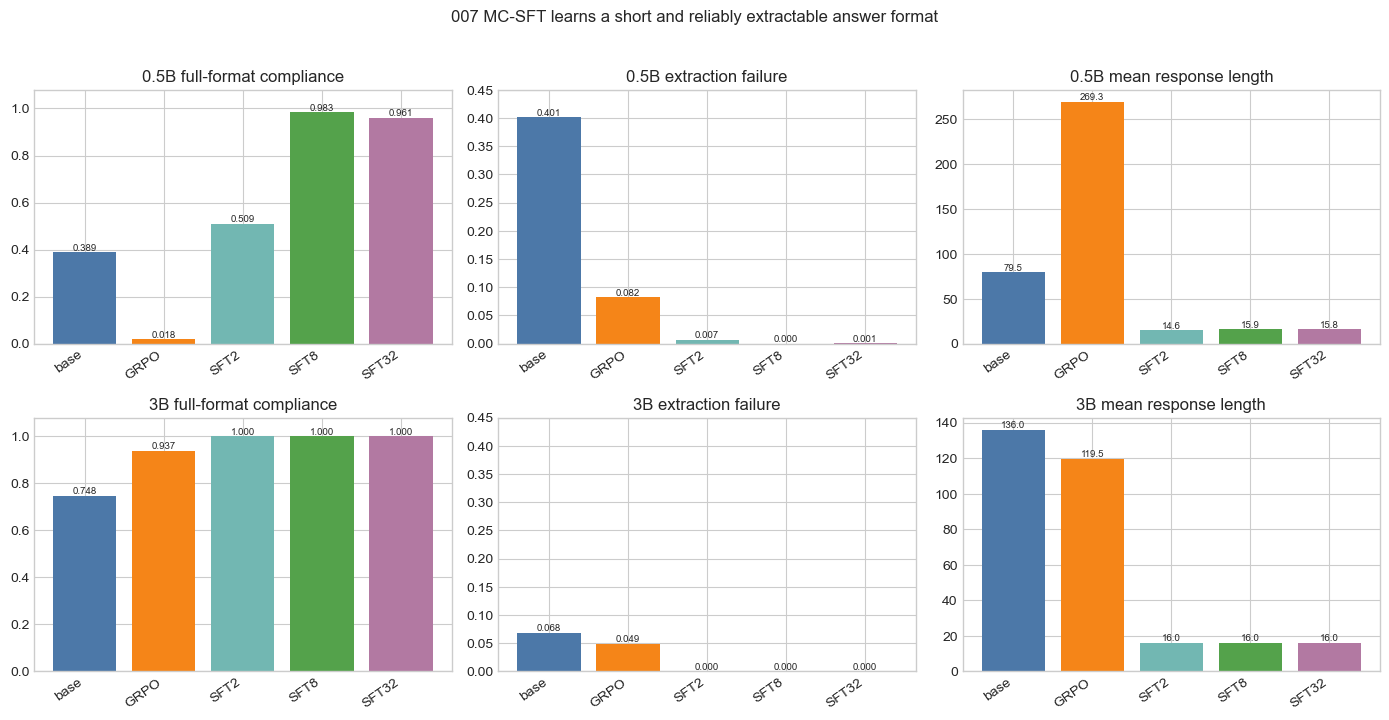

In [28]:
# compare format, extraction and response length for every endpoint
diagnostic_rows = []
for scale in SCALES:
    source_rows = {
        "base": REFS[scale]["gen"]["base"],
        "grpo": REFS[scale]["gen"]["grpo"],
        **{exposure: RUNS[scale][exposure][0]["gen"] for exposure in EXPOSURES},
    }
    for method, rows in source_rows.items():
        diagnostic_rows.append({"scale": scale, "method": method, **diagnosis(rows)})
diagnostic_df = pd.DataFrame(diagnostic_rows)
display(diagnostic_df.assign(scale=diagnostic_df["scale"].map(SCALE_LABELS),
                             method=diagnostic_df["method"].map(METHOD_LABELS))
        .set_index(["scale", "method"]).round(4))

fig, axes = plt.subplots(2, 3, figsize=(14, 7.3))
metric_specs = [
    ("format_compliance", "full-format compliance", (0, 1.08)),
    ("extraction_failure", "extraction failure", (0, 0.45)),
    ("mean_length", "mean response length", None),
]
for row_index, scale in enumerate(SCALES):
    part = diagnostic_df[diagnostic_df["scale"] == scale].set_index("method").loc[METHODS]
    for col_index, (metric, title, limits) in enumerate(metric_specs):
        ax = axes[row_index, col_index]
        values = part[metric].to_numpy()
        bars = ax.bar(np.arange(len(METHODS)), values, color=[COLORS[method] for method in METHODS])
        for bar, value in zip(bars, values):
            label = f"{value:.1f}" if metric == "mean_length" else f"{value:.3f}"
            ax.text(bar.get_x() + bar.get_width() / 2, value, label, ha="center", va="bottom", fontsize=7)
        ax.set_xticks(np.arange(len(METHODS)))
        ax.set_xticklabels(["base", "GRPO", "SFT2", "SFT8", "SFT32"], rotation=35, ha="right")
        ax.set_title(f"{SCALE_LABELS[scale]} {title}")
        if limits:
            ax.set_ylim(*limits)
fig.suptitle("007 MC-SFT learns a short and reliably extractable answer format")
fig.tight_layout(rect=[0, 0, 1, 0.96])
save(fig, "fig07_eval_diagnostics")
plt.show()


saved fig08_subject_accuracy_matrix


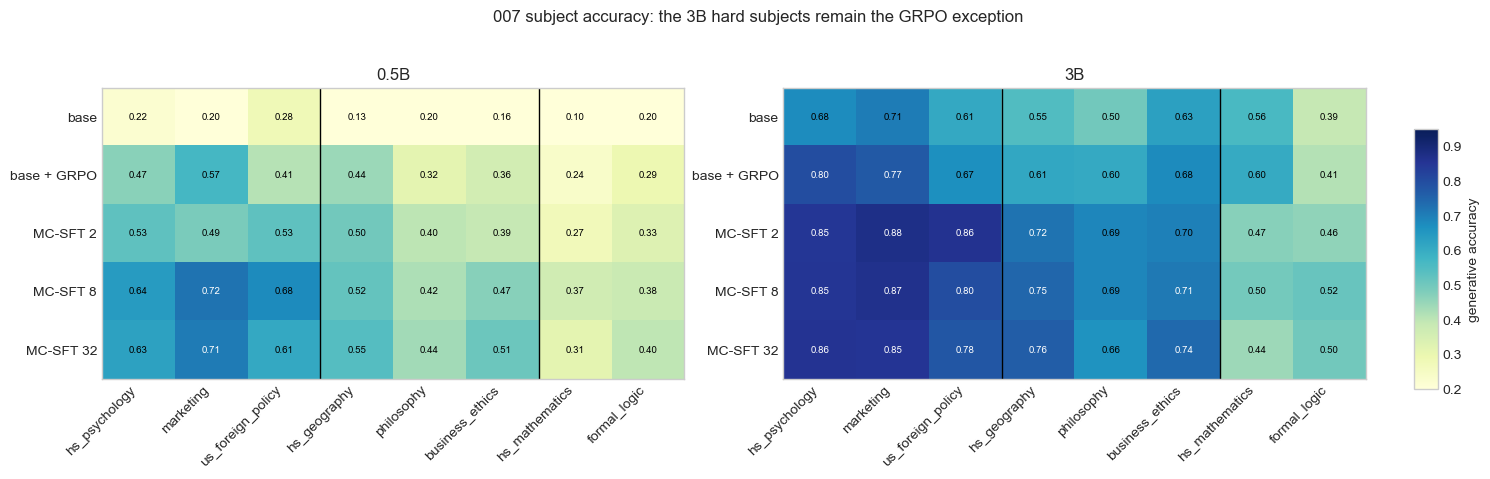

In [29]:
# compare subject accuracy without white seams between heatmap cells
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for ax, scale in zip(axes, SCALES):
    source_rows = {
        "base": REFS[scale]["gen"]["base"],
        "grpo": REFS[scale]["gen"]["grpo"],
        **{exposure: RUNS[scale][exposure][0]["gen"] for exposure in EXPOSURES},
    }
    matrix = np.array([
        [subject_accuracy(source_rows[method])[subject] for subject in SUBJECTS]
        for method in METHODS
    ])
    image = ax.imshow(matrix, cmap="YlGnBu", vmin=0.2, vmax=0.95, aspect="auto", interpolation="nearest")
    ax.set_xticks(np.arange(len(SUBJECTS)))
    ax.set_xticklabels(SHORT_SUBJECTS, rotation=45, ha="right")
    ax.set_yticks(np.arange(len(METHODS)))
    ax.set_yticklabels([METHOD_LABELS[method] for method in METHODS])
    ax.set_title(SCALE_LABELS[scale])
    ax.grid(False)
    ax.axvline(2.5, color="black", lw=1)
    ax.axvline(5.5, color="black", lw=1)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            color = heatmap_text_color(image, matrix[i, j])
            ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=7, color=color)
cbar_axis = fig.add_axes([0.91, 0.25, 0.015, 0.5])
fig.colorbar(image, cax=cbar_axis, label="generative accuracy")
fig.suptitle("007 subject accuracy: the 3B hard subjects remain the GRPO exception")
fig.subplots_adjust(left=0.09, right=0.88, bottom=0.27, top=0.83, wspace=0.17)
save(fig, "fig08_subject_accuracy_matrix")
plt.show()


## 5. Tier-grouping sensitivity

The current validated tiers swap business ethics and US foreign policy relative to the proposal.
The table recalculates every MC-SFT minus GRPO tier delta under both definitions. This checks
that the 007 interpretation is not created by the tier update.


In [30]:
# recalculate the paired tier comparison under both groupings
tier_sensitivity_rows = []
for scale in SCALES:
    for exposure in EXPOSURES:
        for group in ["easy", "medium", "hard"]:
            values = {}
            for label, grouping in [("validated", VALIDATED_TIERS), ("proposal", TIERS_PROPOSAL)]:
                grpo_rows = retag(REFS[scale]["gen"]["grpo"], grouping)
                sft_rows = retag(RUNS[scale][exposure][0]["gen"], grouping)
                values[label] = accuracy(sft_rows, group) - accuracy(grpo_rows, group)
            tier_sensitivity_rows.append({
                "scale": SCALE_LABELS[scale],
                "exposure": exposure,
                "tier": group,
                "validated_delta": values["validated"],
                "proposal_delta": values["proposal"],
                "difference": values["validated"] - values["proposal"],
            })
tier_sensitivity_tbl = pd.DataFrame(tier_sensitivity_rows).set_index(["scale", "exposure", "tier"])
display(tier_sensitivity_tbl.round(4))
print("largest absolute change from tier definition:",
      f"{tier_sensitivity_tbl['difference'].abs().max() * 100:.2f} percentage points")


validated_delta  proposal_delta  difference
scale exposure tier                                               
0.5B  p2       easy             0.0296          0.0193      0.0102
               medium           0.0673          0.0821     -0.0148
               hard             0.0354          0.0354      0.0000
      p8       easy             0.1786          0.1604      0.0182
               medium           0.0969          0.1232     -0.0263
               hard             0.1162          0.1162      0.0000
      p32      easy             0.1581          0.1524      0.0057
               medium           0.1199          0.1281     -0.0082
               hard             0.0859          0.0859      0.0000
3B    p2       easy             0.0796          0.0603      0.0193
               medium           0.0821          0.1100     -0.0279
               hard            -0.0758         -0.0758      0.0000
      p8       easy             0.0739          0.0626      0.0114
               medium           0.0920          0.1084     -0.0164
               hard            -0.0404         -0.0404      0.0000
      p32      easy             0.0705          0.0648      0.0057
               medium           0.0887          0.0969     -0.0082
               hard            -0.0833         -0.0833      0.0000

largest absolute change from tier definition: 2.79 percentage points


## 6. Compact result tables


In [31]:
# keep the headline overall values in one compact table
headline_rows = []
for scale in SCALES:
    base_probe = accuracy(REFS[scale]["probe"]["base"])
    grpo_gen = accuracy(REFS[scale]["gen"]["grpo"])
    for exposure in EXPOSURES:
        probe_part = probe_summary[(probe_summary["scale"] == scale) &
                                   (probe_summary["exposure"] == exposure) &
                                   (probe_summary["group"] == "overall")].iloc[0]
        available_seeds = SEEDS if exposure == "p8" else [0]
        gen_values = [accuracy(RUNS[scale][exposure][seed]["gen"]) for seed in available_seeds]
        diagnostic_values = [diagnosis(RUNS[scale][exposure][seed]["gen"]) for seed in available_seeds]
        diagnostics = {key: np.mean([row[key] for row in diagnostic_values]) for key in diagnostic_values[0]}
        headline_rows.append({
            "scale": SCALE_LABELS[scale],
            "passes": PASSES[exposure],
            "probe_mean_3_seeds": probe_part["mean"],
            "probe_std_3_seeds": probe_part["std"],
            "probe_delta_from_base": probe_part["mean"] - base_probe,
            "gen_seed_count": len(gen_values),
            "gen_mean_available": np.mean(gen_values),
            "gen_std_available": np.std(gen_values, ddof=1) if len(gen_values) > 1 else np.nan,
            "gen_min_available": np.min(gen_values),
            "gen_max_available": np.max(gen_values),
            "gen_delta_mean_vs_grpo_s0": np.mean(gen_values) - grpo_gen,
            **diagnostics,
        })
headline_tbl = pd.DataFrame(headline_rows).set_index(["scale", "passes"])
display(headline_tbl.round(4))


probe_mean_3_seeds  probe_std_3_seeds  probe_delta_from_base  \
scale passes                                                                 
0.5B  2                   0.5642             0.0040                -0.0027   
      8                   0.5563             0.0030                -0.0106   
      32                  0.5517             0.0045                -0.0152   
3B    2                   0.7412             0.0003                 0.0028   
      8                   0.7475             0.0006                 0.0092   
      32                  0.7465             0.0036                 0.0081   

              gen_seed_count  gen_mean_available  gen_std_available  \
scale passes                                                          
0.5B  2                    1              0.4421                NaN   
      8                    3              0.5340             0.0040   
      32                   1              0.5297                NaN   
3B    2                    1              0.7245                NaN   
      8                    3              0.7309             0.0047   
      32                   1              0.7208                NaN   

              gen_min_available  gen_max_available  gen_delta_mean_vs_grpo_s0  \
scale passes                                                                    
0.5B  2                  0.4421             0.4421                     0.0430   
      8                  0.5303             0.5382                     0.1348   
      32                 0.5297             0.5297                     0.1306   
3B    2                  0.7245             0.7245                     0.0478   
      8                  0.7256             0.7346                     0.0541   
      32                 0.7208             0.7208                     0.0441   

              format_compliance  extraction_failure  mean_length  
scale passes                                                      
0.5B  2                  0.5090              0.0069      14.5833  
      8                  0.9496              0.0000      15.7850  
      32                 0.9613              0.0005      15.8466  
3B    2                  1.0000              0.0000      15.9835  
      8                  1.0000              0.0000      15.9988  
      32                 1.0000              0.0000      16.0000

In [32]:
# write the conclusion from the calculated values
def headline_value(scale_label, passes, column):
    return float(headline_tbl.loc[(scale_label, passes), column])

b05_delta = headline_value("0.5B", 8, "gen_delta_mean_vs_grpo_s0")
b3_delta = headline_value("3B", 8, "gen_delta_mean_vs_grpo_s0")
b05_gen_min = headline_value("0.5B", 8, "gen_min_available")
b05_gen_max = headline_value("0.5B", 8, "gen_max_available")
b3_gen_min = headline_value("3B", 8, "gen_min_available")
b3_gen_max = headline_value("3B", 8, "gen_max_available")
b05_probe = headline_value("0.5B", 8, "probe_delta_from_base")
b3_probe = headline_value("3B", 8, "probe_delta_from_base")
def p8_mean_delta(scale, group):
    part = gen_summary[(gen_summary["scale"] == scale) & (gen_summary["method"] == "p8") &
                       (gen_summary["group"] == group)].iloc[0]
    return float(part["mean"] - accuracy(REFS[scale]["gen"]["grpo"], group))
b05_hard = p8_mean_delta("B05", "hard")
b3_hard = p8_mean_delta("B3", "hard")

display(Markdown(f"""## Cross-referenced conclusion

All 18 probe runs and all ten generative evaluations finished correctly. The seed-0 exposure
curve reaches its highest overall value at 8 passes for both scales. The 8-pass result is stable
across its three generative seeds: **{b05_gen_min * 100:.1f}% to {b05_gen_max * 100:.1f}%** at
0.5B and **{b3_gen_min * 100:.1f}% to {b3_gen_max * 100:.1f}%** at 3B. Its three-seed mean is
**{b05_delta * 100:+.1f} points** above the seed-0 base-to-GRPO artifact at 0.5B and
**{b3_delta * 100:+.1f} points** above it at 3B. These last differences are sensitivity
comparisons because the GRPO reference still has one seed.

The three-seed probe does not show the same movement. At 8 passes its mean change from the
base probe is only **{b05_probe * 100:+.1f} points** at 0.5B and
**{b3_probe * 100:+.1f} points** at 3B. Together with the short outputs and high format
compliance, this says MC-SFT mainly teaches the model to express the answer it already prefers.
It strongly weakens a claim that GRPO is necessary for the large easy and medium generative
gains in these runs.

The hard tier is not the same at both scales. At 8 passes MC-SFT is
**{b05_hard * 100:+.1f} points** relative to GRPO at 0.5B, but
**{b3_hard * 100:+.1f} points** at 3B. GRPO stays ahead on 3B hard at all three MC-SFT
budgets, so formal reasoning at the larger scale remains the main place where GRPO may add
something that the fixed supervised target does not reproduce.

This is still exploratory. The 2-pass and 32-pass generative points have one seed, the exposure
curve is not monotonic, and each budget has a different learning-rate decay. The paired method
tests remain seed-0 artifact comparisons. The comparison is between complete methods as
practised, not an isolation of the SFT and GRPO objectives alone.
"""))


## Cross-referenced conclusion

All 18 probe runs and all ten generative evaluations finished correctly. The seed-0 exposure
curve reaches its highest overall value at 8 passes for both scales. The 8-pass result is stable
across its three generative seeds: **53.0% to 53.8%** at
0.5B and **72.6% to 73.5%** at 3B. Its three-seed mean is
**+13.5 points** above the seed-0 base-to-GRPO artifact at 0.5B and
**+5.4 points** above it at 3B. These last differences are sensitivity
comparisons because the GRPO reference still has one seed.

The three-seed probe does not show the same movement. At 8 passes its mean change from the
base probe is only **-1.1 points** at 0.5B and
**+0.9 points** at 3B. Together with the short outputs and high format
compliance, this says MC-SFT mainly teaches the model to express the answer it already prefers.
It strongly weakens a claim that GRPO is necessary for the large easy and medium generative
gains in these runs.

The hard tier is not the same at both scales. At 8 passes MC-SFT is
**+9.6 points** relative to GRPO at 0.5B, but
**-4.3 points** at 3B. GRPO stays ahead on 3B hard at all three MC-SFT
budgets, so formal reasoning at the larger scale remains the main place where GRPO may add
something that the fixed supervised target does not reproduce.

This is still exploratory. The 2-pass and 32-pass generative points have one seed, the exposure
curve is not monotonic, and each budget has a different learning-rate decay. The paired method
tests remain seed-0 artifact comparisons. The comparison is between complete methods as
practised, not an isolation of the SFT and GRPO objectives alone.
